# Autoencoders

Companion notebook for the *Autoencoders* slides. Each idea is written first by hand
with NumPy and then checked with scikit-learn or with an independent computation.

**Data:** the scikit-learn digits (1797 pictures of 8 × 8 pixels, $d = 64$, scaled to $[0, 1]$); the labels are used only to color plots.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
from scipy.integrate import quad
from scipy.stats import norm
from sklearn.datasets import load_digits
from sklearn.decomposition import PCA
from sklearn.metrics import mean_squared_error
from sklearn.model_selection import train_test_split
from sklearn.neural_network import MLPRegressor

RANDOM_STATE = 42
CODE_SIZE = 2
LEARNING_RATE = 0.1
STEPS = 3000

X, labels = load_digits(return_X_y=True)
X = X / 16
X_train, X_test, labels_train, labels_test = train_test_split(X, labels, test_size=0.3, random_state=RANDOM_STATE)
rng = np.random.default_rng(RANDOM_STATE)

## 1. The reconstruction loss

$J = \frac{1}{n}\sum_i \lVert \mathbf{x}_i - \hat{\mathbf{x}}_i \rVert^2$, the slide's example with two examples of 3 features.

In [2]:
x = np.array([[1, 0, 2], [0, 1, 1]])
x_hat = np.array([[0.8, 0.1, 1.7], [0.2, 0.9, 1.0]])
J = np.mean(np.sum((x - x_hat) ** 2, axis=1))

# scikit-learn averages over the 3 features too, so multiply by d
print(f"J = {J:.3f} | same result:", np.isclose(J, 3 * mean_squared_error(x, x_hat)))

J = 0.095 | same result: True


## 2. A linear autoencoder finds the PCA subspace

Encoder $\mathbf{z} = \mathbf{W}_1\mathbf{x}$, decoder $\hat{\mathbf{x}} = \mathbf{W}_2\mathbf{z}$ (no activation, centered data),
trained by gradient descent $\boldsymbol\theta \leftarrow \boldsymbol\theta - \alpha\nabla_{\boldsymbol\theta} J$ with code size $q = 2$.

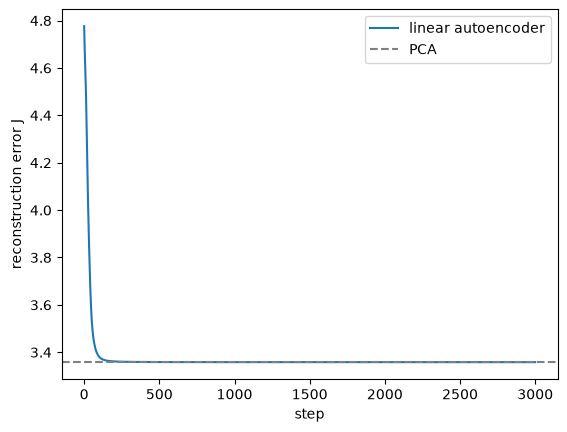

In [3]:
mean = X_train.mean(axis=0)
X_centered = X_train - mean
W1 = rng.normal(0, 0.1, (CODE_SIZE, X.shape[1]))
W2 = rng.normal(0, 0.1, (X.shape[1], CODE_SIZE))
losses = []
for _ in range(STEPS):
    Z = X_centered @ W1.T
    residual = Z @ W2.T - X_centered
    losses.append(np.mean(np.sum(residual ** 2, axis=1)))
    grad_W2 = 2 * residual.T @ Z / len(X_centered)
    grad_W1 = 2 * (residual @ W2).T @ X_centered / len(X_centered)
    W1 -= LEARNING_RATE * grad_W1
    W2 -= LEARNING_RATE * grad_W2

pca = PCA(n_components=CODE_SIZE).fit(X_train)
pca_error = np.mean(np.sum((pca.inverse_transform(pca.transform(X_train)) - X_train) ** 2, axis=1))

plt.plot(losses, label="linear autoencoder")
plt.axhline(pca_error, color="gray", linestyle="--", label="PCA")
plt.xlabel("step")
plt.ylabel("reconstruction error J")
plt.legend()
plt.show()

The two codes can be rotated versions of each other, so we compare the subspaces (their projection matrices), not the weights.

In [4]:
Q, _ = np.linalg.qr(W2)
print("same error:", np.isclose(losses[-1], pca_error, rtol=1e-3))
print("same subspace:", np.allclose(Q @ Q.T, pca.components_.T @ pca.components_, atol=1e-3))

same error: True
same subspace: True


## 3. A nonlinear autoencoder

An `MLPRegressor` trained to output its own input is an autoencoder: layers $64 \to 64 \to 2 \to 64 \to 64$ with tanh.
The encoder is the first half: $\mathbf{z} = g(\mathbf{W}\,g(\mathbf{W}\mathbf{x} + \mathbf{b}) + \mathbf{b})$.

In [5]:
autoencoder = MLPRegressor(hidden_layer_sizes=(64, CODE_SIZE, 64), activation="tanh", learning_rate_init=0.003,
                           tol=1e-6, n_iter_no_change=20, max_iter=3000, random_state=RANDOM_STATE).fit(X_train, X_train)

layer = X_test
for i, (W, b) in enumerate(zip(autoencoder.coefs_, autoencoder.intercepts_)):
    layer = layer @ W + b
    if i < len(autoencoder.coefs_) - 1:
        layer = np.tanh(layer)
    if i == 1:
        codes = layer

print("same result:", np.allclose(layer, autoencoder.predict(X_test)))
mlp_error = np.mean(np.sum((layer - X_test) ** 2, axis=1))
pca_test_error = np.mean(np.sum((pca.inverse_transform(pca.transform(X_test)) - X_test) ** 2, axis=1))
print(f"test reconstruction error with a code of 2: autoencoder {mlp_error:.2f}, PCA {pca_test_error:.2f}")

same result: True
test reconstruction error with a code of 2: autoencoder 2.26, PCA 3.36


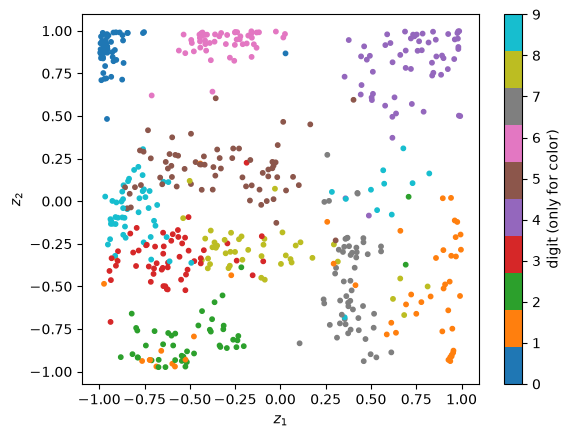

In [6]:
plt.scatter(codes[:, 0], codes[:, 1], c=labels_test, cmap="tab10", s=10)
plt.colorbar(label="digit (only for color)")
plt.xlabel("$z_1$")
plt.ylabel("$z_2$")
plt.show()

## 4. Spotting odd examples

$s(\mathbf{x}) = \lVert \mathbf{x} - g_{\boldsymbol\psi}(f_{\boldsymbol\phi}(\mathbf{x})) \rVert^2$: flag $\mathbf{x}$ if $s(\mathbf{x}) > \tau$.
The odd examples here are pictures of random noise; $\tau$ is the 99th percentile of the scores on training digits.

In [7]:
def score(images: np.ndarray) -> np.ndarray:
    return np.sum((images - autoencoder.predict(images)) ** 2, axis=1)


tau = np.percentile(score(X_train), 99)
noise_images = rng.uniform(0, 1, (50, X.shape[1]))
print(f"flagged: {np.mean(score(X_test) > tau):.0%} of new digits, {np.mean(score(noise_images) > tau):.0%} of noise pictures")

per_example_mse = mean_squared_error(X_test.T, autoencoder.predict(X_test).T, multioutput="raw_values")
print("same result:", np.allclose(score(X_test), X.shape[1] * per_example_mse))

flagged: 4% of new digits, 100% of noise pictures
same result: True


## 5. Variational autoencoder: sampling the code

Reparameterization: $\mathbf{z} = \boldsymbol\mu + \boldsymbol\sigma \odot \boldsymbol\epsilon$, $\boldsymbol\epsilon \sim \mathcal{N}(\mathbf{0}, \mathbf{I})$.
The penalty is $\text{KL} = \sum_j \tfrac12(\mu_j^2 + \sigma_j^2 - 1 - \ln\sigma_j^2)$.

In [8]:
mu, sigma = np.array([1.0, -0.5]), np.array([0.5, 2.0])
z = mu + sigma * rng.normal(size=(100_000, 2))
print("sample mean and spread match mu and sigma (tolerance 0.02):",
      np.allclose(z.mean(axis=0), mu, atol=0.02) and np.allclose(z.std(axis=0), sigma, atol=0.02))

sample mean and spread match mu and sigma (tolerance 0.02): True


Independent check of the KL formula for one code dimension: integrate $\int q(z)\,\ln\frac{q(z)}{p(z)}\,dz$ numerically,
with $q = \mathcal{N}(\mu, \sigma^2)$ and $p = \mathcal{N}(0, 1)$.

In [9]:
mu_1, sigma_1 = 1.0, 0.5
kl_by_hand = 0.5 * (mu_1 ** 2 + sigma_1 ** 2 - 1 - np.log(sigma_1 ** 2))
kl_numeric, _ = quad(lambda t: norm.pdf(t, mu_1, sigma_1) * (norm.logpdf(t, mu_1, sigma_1) - norm.logpdf(t)), -10, 10)
print(f"KL = {kl_by_hand:.3f} | same result:", np.isclose(kl_by_hand, kl_numeric))

KL = 0.818 | same result: True


## Exercises

1. Change `CODE_SIZE` to 10 in section 2. Does the linear autoencoder still match PCA?
2. Train the section 3 autoencoder on noisy copies `X_train + noise` with target `X_train` (denoising) and compare its error on noisy test digits.
3. In section 4, use the digits 0 to 4 as normal data and the digits 5 to 9 as odd ones. How many are flagged?